# Spectral hole burning in Pr:YSO

Worked through linearly. Run the cells in order.



## 1. Config

In [ ]:

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
from worker import * # Moved functions to worker.py, see explanation in cell 2

# the following 3 imports are use for multiprocessing the code
from multiprocessing import Pool
from functools import partial
import numpy as np


# Where the figures appear. "vscode" draws them inline in the notebook;
# "browser" opens each one in a new tab; "notebook" / "notebook_connected"
# for classic Jupyter or JupyterLab. Leaving it as None lets plotly work it
# out for itself, which is usually right.
pio.renderers.default = "vscode"

# Every plot is drawn twice: plotly to look at on screen, matplotlib for
# the write-up. The matplotlib figures use signature.mplstyle, the same
# style sheet as mbe_simulation.ipynb, so the two sets of figures match.
plt.style.use("signaturempl.txt")

params = dict(

    crystal_params = {


        #        +-5/2(g)      +-3/2(g)  +-1/2(g)
        'g': [-(10.19 + 17.30),    -10.19,      0.00],   # MHz

        #        +-1/2(e)  +-3/2(e)     +-5/2(e)
        'e': [        0.00,      4.58,   4.58 + 4.84],   # MHz

        # Relative transition strengths, Nilsson et al. 2004 Table 1
        # and sharma et al. 2023

        #                to:  +-1/2(e)  +-3/2(e)  +-5/2(e)
        'dm': np.array([
            [                    0.052,    0.022,    0.926],   # from +-5/2(g)
            [                    0.396,    0.596,    0.008],   # from +-3/2(g)
            [                    0.552,    0.382,    0.066],   # from +-1/2(g)
        ]),
    },

    linewidth_params = {
        'h_width':  0.001,        # homogeneous FWHM (MHz), Lorentzian
        'in_width': 10000.0,      # inhomogeneous FWHM (MHz), Gaussian
    },

    numerical_params = {
        'fmin': -50.0,            # spectrum window, low edge (MHz)
        'fmax':  50.0,            # spectrum window, high edge (MHz)
        'df':    0.001,            # mesh step (MHz)
                                  #
                                  # df MUST DIVIDE THE LEVEL ENERGIES ABOVE
                                  # EXACTLY, and the window edges with them.
                                  # The levels are given to one decimal place
                                  # (10.2, 17.3, 4.6, 4.8), so 0.1, 0.05,
                                  # 0.02, 0.01, 0.005 and 0.001 are all fine;
                                  # 0.03, 0.04 and 0.07 will not work.

    },

    burn_params = {
        'pump_passes': 1,         # how many times to repeat the pump list.
 
    },

    output_params = {
        'alpha': 1.0,          # Abs coefficient (1/m) (1/m chosen to correspond with Bloch-Simulator). Set to 1 for normalised Abs
        'norm':  None,            # peak of the unburned spectrum - computed
                                  # just below, every time this cell is run.
    },
)

# Moved settings function to worker.py too

# The normalisation factor sets the OD scale, and it depends on df, h_width,
# in_width and the transitions. After the next cell has run at least once you can just re-run this cell 
# if any of the parameters are changed.
if 'normalisation_factor' in globals():
    params['output_params']['norm'] = normalisation_factor(params)
    print(f"normalisation factor: {params['output_params']['norm']:.6f}")
else:
    print("Run cell 2 next - it defines the simulator and computes the "
          "normalisation.")

normalisation factor: 1.712673


## 2. SHB simulator

In [ ]:
# Moved code in this cell to worker.py 
# import it with "from worker import *" and all the functions just behave the same way as if they were here. 
# This is required for multiprocessing module which wants to call a separate version of the function on each thread and it can't do that from the notebook.

normalisation factor: 1.712673


---
## 3. A single hole

The simplest burn: one pump frequency, burned ten times over.

1 pump frequency, 10 passes
OD 1 to 1


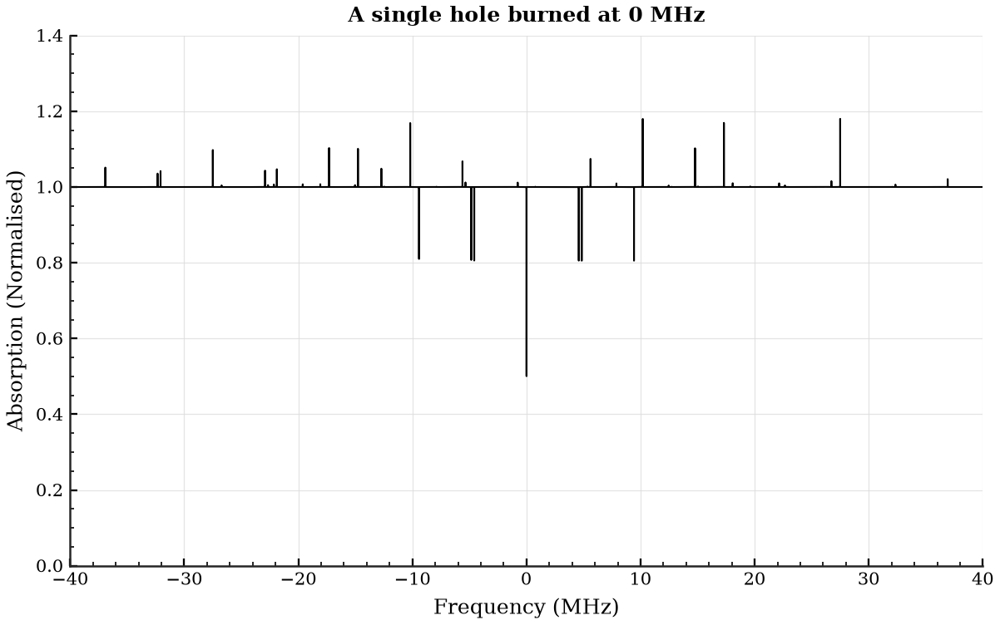

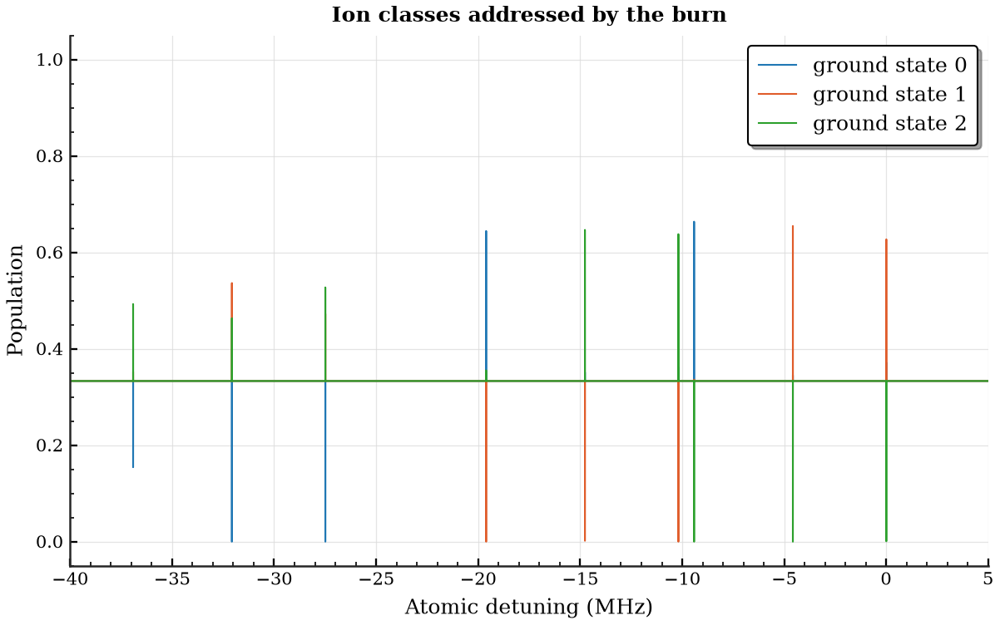

In [48]:

def single_hole(centre=0.0):
    """One pump frequency, at `centre` MHz."""
    return np.array([centre])


pump_freqs = single_hole(centre=0.0)

out = run_burn(pump_freqs, params, burn=burn_parallel, pump_passes=10)

print(f"{len(pump_freqs)} pump frequency, 10 passes")
print(f"OD {out['spec'].min():.0f} to {out['spec'].max():.0f}")

#PLOT SPECTRUM
fig = go.Figure()
fig.add_hline(y=settings(params)['alpha'], line_dash="dash",
              line_color="#94A3B8", line_width=1)
fig.add_trace(go.Scatter(x=out['f'], y=out['spec'], mode="lines",
                         line=dict(width=0.9, color="#C05621"),
                         name="spectrum"))
fig.update_layout(title="A single hole burned at 0 MHz, 10 passes",
                  xaxis_title="Frequency (MHz)",
                  yaxis_title="Absorption (OD)",
                  template="plotly_white")
fig.show()

#PLOT ADDRESSED ION CLASSES
fig = go.Figure()
for k in range(out['rho'].shape[0]):
    fig.add_trace(go.Scatter(x=out['det'], y=out['rho'][k], mode="lines",
                             line=dict(width=1.1),
                             name=f"ground state {k}"))
fig.update_layout(title="Ion classes addressed by the burn",
                  xaxis_title="Atomic detuning (MHz)",
                  yaxis_title="Population",
                  template="plotly_white")
fig.show()

# --- matplotlib versions, for the write-up ---------------------------------
p = settings(params)

# --- PLOT 1: Optical Spectrum ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(p['alpha'], color='0.5', lw=0.8, ls='--', label='unburned')
ax.plot(out['f'], out['spec'], color='black', lw=1, label='spectrum')

# Limit axis ranges here
ax.set_xlim(-40, 40)           # Zooms in on the 0 MHz burned hole region
ax.set_ylim(0.0, 1.4)         # Enforces standard normalised range (with padding)

ax.set_xlabel(r'Frequency (MHz)')
ax.set_ylabel(r'Absorption (Normalised)')
ax.set_title(r'A single hole burned at 0 MHz')
#ax.legend()
fig.savefig("single_hole_spectrum.png")
plt.show()

# --- PLOT 2: Ion Populations ---
fig, ax = plt.subplots(figsize=(8, 5))
for k in range(out['rho'].shape[0]):
    ax.plot(out['det'], out['rho'][k], lw=1, label=f"ground state {k}")

# Limit axis ranges here
ax.set_xlim(-40, 5)           # Adjust based on the width of your laser interactions
ax.set_ylim(-0.05, 1.05)       # Population fractional range (from 0 to 1)

ax.set_xlabel(r'Atomic detuning (MHz)')
ax.set_ylabel(r'Population')
ax.set_title(r'Ion classes addressed by the burn')
ax.legend()
fig.savefig("single_hole_populations.png")
plt.show()

---
## 4. Scanning tooth spacing and burn width percentage

Sweeps tooth spacing against burn width, scoring each spectrum by its
ΔOD over a window at the centre.

The scan runs on the config's window and mesh, and steps the tooth spacing.

The cost of a fixed window is the wide end: a 10 MHz tooth spacing has to fit
inside the same +-20 MHz that a 0.1 MHz spacing uses, which leaves only five
teeth. 


### The scan

In [ ]:


import heapq
import time
import numpy as np
from tqdm import tqdm



def comb(spacing_steps, width_steps, params):
    """
    Teeth every spacing_steps bins across the spectrum window, each tooth
    width_steps bins wide.

    """
    p = settings(params)
    df = p['df']
    f0 = int(to_steps(p['fmin'], df))
    f1 = int(to_steps(p['fmax'], df))

    n_teeth = (f1 - f0) // spacing_steps + 1
    starts = f0 + spacing_steps * np.arange(n_teeth)
    return df * (starts[:, None] + np.arange(width_steps)[None, :]).ravel()


def run_scan(spacing_min, spacing_max, spacing_step,
             n_widths, target_window, top_n, pump_passes):
    """
    Sweep tooth spacing and burn width, scoring each spectrum by its
    delta OD over a window at the centre.

    The spectrum window and mesh come from the config - fmin, fmax and df cant be changed here. 
    Change them in cell 1 and re-run it to re-normalise

    spacing_min/max  range of tooth spacings to try (MHz)
    spacing_step     increment between them (MHz). All three are converted to
                     whole df steps and must divide by df exactly.
    n_widths         burn widths per spacing - the tooth is divided into this
                     many, so widths run spacing/n
    target_window    judge each spectrum over this width at the centre (MHz).
                     Defaults to 4 x spacing_max, so the judging window always
                     holds several teeth however wide the spacing gets. Be carefull with using this
    top_n            how many of the best spectra to keep for plotting

    Returns a dictionary:
        tag        short name for this scan, used on filenames and titles
        results    (spacing, width, delta_od) for every point, in MHz
        best       the top_n records, largest delta OD first
        params     the parameters this scan ran with (the config)
        n_widths, target_window, pump_passes
    """
    p = settings(params)
    df = p['df']
    tag = f"{spacing_min:g}-{spacing_max:g}MHz"

    # Judge over a window wide enough to hold several teeth at the widest
    # spacing, rather than a fixed width that would hold one tooth or none.
    if target_window is None:
        target_window = spacing_max*4


    s_min = int(to_steps(spacing_min, df))
    s_max = int(to_steps(spacing_max, df))
    s_inc = int(to_steps(spacing_step, df))
    spacing_grid = np.arange(s_min, s_max + 1, s_inc)

    grid = [(int(s), max(1, int(n * s // n_widths)))
            for s in spacing_grid
            for n in range(1, n_widths + 1)]

    # one spectrum,  for the timer
    print(f"[{tag}]  {len(spacing_grid)} spacings, {len(grid)} spectra   "
          f"window {p['fmin']:g} to {p['fmax']:g} MHz, df {df:g}, judged over "
          f"{target_window:g} MHz")

    _t0 = time.time()
    run_burn(comb(*grid[len(grid) // 2], params), params,
             burn=burn_parallel, pump_passes=pump_passes)
    _total = (time.time() - _t0) * len(grid)
    print(f"    about " + (f"{_total:.0f} seconds" if _total < 90
                             else f"{_total / 60:.0f} minutes"))


    # run the scan with multiprocessing ------------------------------------------------------------------------

    # Fix the arguments that don't change per call; each worker only gets the
    # one thing that does: (n, (spacing_steps, width_steps)).
    worker = partial(compute_one, params=params, burn=burn_parallel,
                    pump_passes=pump_passes, df=df, target_window=target_window)

    # Pre-pair (n, grid_item) since pool.imap needs a ready iterable to hand out
    items = list(enumerate(grid))

    results, best = [], []
    with Pool(processes=16) as pool: # TODO Change number of processes depending on machine 
        
        # pool.imap runs `worker` across processes, streaming results back in order
        for result_row, record in tqdm(pool.imap(worker, items),
                                        total=len(items), desc=f"scan {tag}", unit="spec"):
            results.append(result_row)

            # top-N heap — stays in the main process, same as the serial version
            if len(best) < top_n:
                heapq.heappush(best, record)
            elif record[0] > best[0][0]:
                heapq.heappushpop(best, record)

    # ----------------------------------------------------------------------------------------------------------

    return {'tag': tag,
            'results': results,
            'best': sorted(best, key=lambda r: r[0], reverse=True),
            'params': params,
            'n_widths': n_widths,
            'target_window': target_window,
            'pump_passes': pump_passes}


### The three plots

In [59]:
# Matplotlib versions for the write-up, plotly versions for looking at on
# screen. The matplotlib ones follow signature.mplstyle - the same style
# sheet as mbe_simulation.ipynb - so figures from both notebooks match.
import matplotlib.ticker as mtick

#-------------------------------------------------------------------------------------------------------------------
def plot_heatmap_mp(scan, save=True):
    """ΔOD over tooth spacing and burn width fraction."""
    n_widths = scan['n_widths']
    res = scan['results']

    spacing_vals = np.array(sorted({s for s, w, d in res}))

    def fraction(s, w):
        return round(w / s * n_widths) / n_widths

    frac_vals = np.array(sorted({fraction(s, w) for s, w, d in res}))

    z = np.full((len(frac_vals), len(spacing_vals)), np.nan)
    for s, w, d in res:
        col = int(np.searchsorted(spacing_vals, s))
        row = int(np.searchsorted(frac_vals, fraction(s, w)))
        z[row, col] = d

    fig, ax = plt.subplots(figsize=(8, 3))

    # shading='nearest' centres each pixel on its spacing and fraction. Any
    # combination the scan did not visit stays NaN and is drawn blank.
    mesh = ax.pcolormesh(spacing_vals, frac_vals, z, shading='nearest')
    fig.colorbar(mesh, ax=ax, label=r'$\Delta$Absorption')

    ax.set_title(f"Comb $\\Delta$Absorption over the central "
                 f"{scan['target_window']:g} MHz")
    ax.set_xlabel(r'Tooth spacing (MHz)')
    ax.set_ylabel(r'Burn width percentage')
    ax.set_ylim(0, 0.95)    
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

    # Saved before it is shown: on the inline backend a figure can be cleared
    # by show, and a blank png written instead.
    if save:
        fig.savefig(f"DeltaOD_heatmap_{scan['tag']}.png")
    plt.show()


def plot_max_dod_mp(scan, save=True):
    """The best ΔOD achievable at each tooth spacing."""
    res = scan['results']

    best_per = {}
    for s, w, d in res:
        if s not in best_per or d > best_per[s][0]:
            best_per[s] = (d, w)

    spacing_vals = np.array(sorted(best_per))
    max_dod = np.array([best_per[s][0] for s in spacing_vals])
    best_width = np.array([best_per[s][1] for s in spacing_vals])

    fig, ax = plt.subplots(figsize=(8, 3))

    ax.plot(spacing_vals, max_dod, color='C0', lw=1.8,
            label=r'best $\Delta$Absorption')

    # Ring the best point rather than marking every one - at 0.05 MHz steps
    # there are far too many spacings for markers to read.
    i = int(np.argmax(max_dod))
    ax.plot(spacing_vals[i], max_dod[i], linestyle='none', marker='o',
            markersize=11, markerfacecolor='none', markeredgecolor='C1',
            markeredgewidth=1.8, label=f"best: {spacing_vals[i]:.2f} MHz")

    ax.set_title(f"Best $\\Delta$Absorption at each tooth spacing")
    ax.set_xlabel(r'Tooth spacing (MHz)')
    ax.set_ylabel(r'Maximum $\Delta$Absorption')
    ax.legend(fontsize=9, loc='lower right')

    if save:
        fig.savefig(f"DeltaOD_vs_toothspacing_{scan['tag']}.png")
    plt.show()

    print(f"[{scan['tag']}] best: \u0394Absorption {max_dod[i]:.0f} at "
          f"{spacing_vals[i]:.2f} MHz, width {best_width[i]:.3f} MHz ")
#---------------------------------------------------------------------------------------------------------



def plot_top_spectra(scan, save=True):
    """The top spectrums overlaid, for visual inspection."""
    p = settings(scan['params'])
    df = p['df']

    fig = go.Figure()
    fig.add_hline(y=p['alpha'], line_dash="dash", line_color="#94A3B8",
                  line_width=1)
    for delta_od, _, spec, tooth_spacing, pulses, f in scan['best']:
        width = pulses * df
        fig.add_trace(go.Scatter(
            x=f, y=spec, mode="lines", line=dict(width=0.7),
            name=f"ΔOD {delta_od:.2f} | spacing {tooth_spacing:.2f} MHz, "
                 f"width {width:.3f} MHz ({width / tooth_spacing:.0%})"))

    fig.update_layout(
        title=f"Top {len(scan['best'])} spectra by ΔOD  ({scan['tag']})"
              f"<br>central {scan['target_window']:g} MHz, window "
              f"±{p['fmax']:g} MHz, df {df:g}, "
              f"{scan['pump_passes']} pass parallel",
        xaxis_title="Frequency (MHz)", yaxis_title="Normalised Absorption",
        template="plotly_white")
    fig.show()
    if save:
        fig.write_html(f"TopSpectra_{scan['tag']}.html")


def plot_heatmap(scan, save=True):
    """ΔOD over tooth spacing and burn width fraction."""
    n_widths = scan['n_widths']
    res = scan['results']

    spacing_vals = np.array(sorted({s for s, w, d in res}))

    def fraction(s, w):
        return round(w / s * n_widths) / n_widths

    frac_vals = np.array(sorted({fraction(s, w) for s, w, d in res}))

    z = np.full((len(frac_vals), len(spacing_vals)), np.nan)
    width_mhz = np.full_like(z, np.nan)
    for s, w, d in res:
        col = int(np.searchsorted(spacing_vals, s))
        row = int(np.searchsorted(frac_vals, fraction(s, w)))
        z[row, col] = d
        width_mhz[row, col] = w

    fig = go.Figure(data=go.Heatmap(
        x=spacing_vals, y=frac_vals, z=z, customdata=width_mhz,
        colorscale="Viridis", colorbar=dict(title="ΔOD"),
        hovertemplate="spacing %{x:.2f} MHz<br>%{y:.0%} of the tooth burned "
                      "(%{customdata:.3f} MHz)<br>ΔOD %{z:.0f}<extra></extra>"))

    fig.update_layout(
        title=f"ΔOD over the central {scan['target_window']:g} MHz  "
              f"({scan['tag']})<br>{len(res)} burns, "
              f"{scan['pump_passes']} pass parallel",
        xaxis_title="Tooth spacing (MHz)",
        yaxis_title="Burn width fraction (pulse width / tooth spacing)",
        yaxis=dict(tickformat=".0%"),
        template="plotly_white")
    fig.show()
    if save:
        fig.write_html(f"DeltaOD_heatmap_{scan['tag']}.html")


def plot_max_dod(scan, save=True):
    """The best ΔOD achievable at each tooth spacing."""
    res = scan['results']

    best_per = {}
    for s, w, d in res:
        if s not in best_per or d > best_per[s][0]:
            best_per[s] = (d, w)

    spacing_vals = np.array(sorted(best_per))
    max_dod = np.array([best_per[s][0] for s in spacing_vals])
    best_width = np.array([best_per[s][1] for s in spacing_vals])

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=spacing_vals, y=max_dod, mode="lines+markers",
        line=dict(width=1.4, color="#C05621"), marker=dict(size=5),
        name="best ΔOD",
        customdata=np.stack([best_width, best_width / spacing_vals], axis=-1),
        hovertemplate="spacing %{x:.2f} MHz<br>ΔOD %{y:.0f}"
                      "<br>best width %{customdata[0]:.3f} MHz "
                      "(%{customdata[1]:.0%})<extra></extra>"))

    i = int(np.argmax(max_dod))
    fig.add_trace(go.Scatter(
        x=[spacing_vals[i]], y=[max_dod[i]], mode="markers",
        marker=dict(size=11, color="rgba(0,0,0,0)",
                    line=dict(color="#2C7A7B", width=2)),
        name=f"best: {spacing_vals[i]:.2f} MHz", hoverinfo="skip"))

    fig.update_layout(
        title=f"Best ΔOD at each tooth spacing  ({scan['tag']})"
              f"<br>central {scan['target_window']:g} MHz, "
              f"{scan['pump_passes']} pass parallel",
        xaxis_title="Tooth spacing (MHz)", yaxis_title="Maximum ΔOD",
        template="plotly_white")
    fig.show()
    if save:
        fig.write_html(f"DeltaOD_vs_toothspacing_{scan['tag']}.html")

    print(f"[{scan['tag']}] best: ΔOD {max_dod[i]:.0f} at "
          f"{spacing_vals[i]:.2f} MHz, width {best_width[i]:.3f} MHz "
          f"({best_width[i] / spacing_vals[i]:.0%} filled)")

### Run the scan



In [60]:
# One scan. Window and mesh come from the config, so the only thing set here
# is the range of tooth spacings and the increment between them 

scan = run_scan(spacing_min=0.2, spacing_max=5.0, spacing_step=0.01, n_widths=10, target_window=20, top_n=50, pump_passes=10)


[0.2-5MHz]  481 spacings, 4810 spectra   window -50 to 50 MHz, df 0.001, judged over 20 MHz


KeyboardInterrupt: 

In [1]:
import pickle
with open("results_20260824_174011.pkl", "rb") as f:
    scan = pickle.load(f)

### Show plots


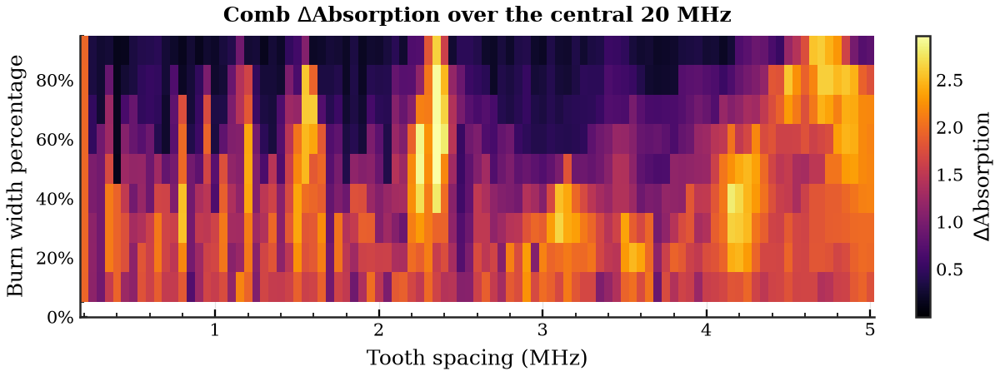

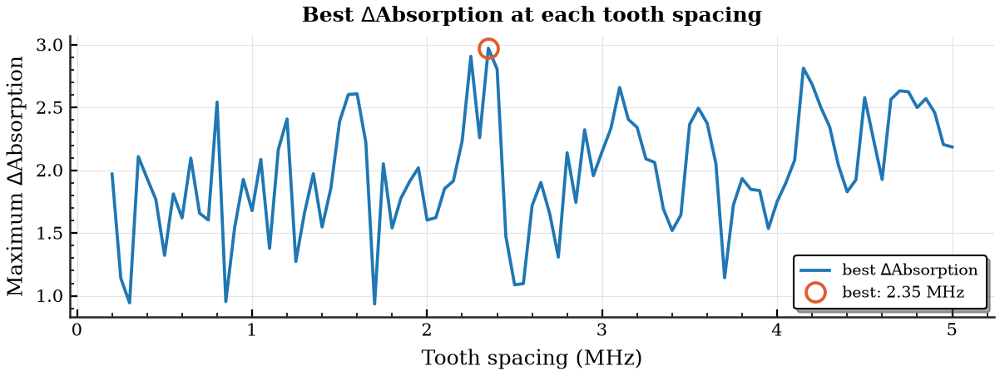

[0.2-5MHz] best: ΔAbsorption 3 at 2.35 MHz, width 1.175 MHz 


[0.2-5MHz] best: ΔOD 3 at 2.35 MHz, width 1.175 MHz (50% filled)


In [ ]:

#Absorption plots for dissertation
plot_heatmap_mp(scan)
plot_max_dod_mp(scan)
#------------------------------

plot_top_spectra(scan)   # I know that this one is awkward but it is really useful to be able to see the best spectrums
                         # It doesnt work perfectly but by clicking on the legend at the side
                         # 3 or 4 times (two double clicks) it eventually isolates a spectrum. 
                         # I found that I needed to keep trying this until it worked
plot_heatmap(scan)
plot_max_dod(scan)


---
## 5. One chosen comb

Pick a comb by hand, run it, save it, plot it.

Set `tooth_spacing` and `burn_width` in the cell below. They can come off the
scan's heatmap, or from a physical argument that has nothing to do with it
the cell does not need a scan to have been run. Again be careful with the mesh.



126 teeth, 6048 pump frequencies, 10 pass parallel
spacing 0.8 MHz, width 0.24 MHz (30% of the tooth filled)
Absorption 0 to 3   (DAbsorption 3, unburned 1)


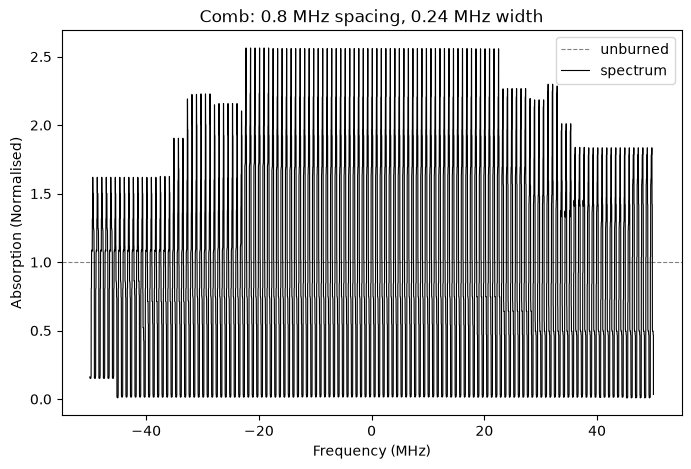

In [ ]:
tooth_spacing = 0.8     # MHz, gap between neighbouring teeth
burn_width    = 0.24     # MHz, how much of each tooth is burned
pump_passes   = 10      # how many times the whole comb is repeated

save_array    = False    # write the .npy
save_html     = False    # write a standalone plotly page
save_png      = False    # write the matplotlib png for the write-up


# --- pump frequencies -------------------------------------------------
def comb_at(tooth_spacing, burn_width, params):
    """
    A comb across the whole config window: teeth every `tooth_spacing` MHz,
    each tooth `burn_width` MHz wide.

    Returns
        freqs           the pump frequencies (MHz), exactly on the mesh
        actual_spacing  the spacing, on the mesh (MHz)
        actual_width    the width, on the mesh (MHz)
        n_teeth         how many teeth fitted in the window
    """
    p = settings(params)
    df = p['df']

    # to_steps rather than round: an off-mesh spacing or width stops here
    spacing_steps = int(to_steps(tooth_spacing, df))
    width_steps   = int(to_steps(burn_width, df))

    f0 = int(to_steps(p['fmin'], df))
    f1 = int(to_steps(p['fmax'], df))

    n_teeth = (f1 - f0) // spacing_steps + 1
    starts = f0 + spacing_steps * np.arange(n_teeth)
    freqs = df * (starts[:, None] + np.arange(width_steps)[None, :]).ravel()

    return freqs, spacing_steps * df, width_steps * df, n_teeth


pump_freqs, actual_spacing, actual_width, n_teeth = comb_at(
    tooth_spacing, burn_width, params)

p = settings(params)

# run the burn
out = run_burn(pump_freqs, params, burn=burn_parallel,
               pump_passes=pump_passes)

f, spec = out['f'], out['spec']
delta_od = spec.max() - spec.min()

print(f"{n_teeth} teeth, {len(pump_freqs)} pump frequencies, "
      f"{pump_passes} pass parallel")
print(f"spacing {actual_spacing:g} MHz, width {actual_width:g} MHz "
      f"({actual_width / actual_spacing:.0%} of the tooth filled)")
print(f"Absorption {spec.min():.0f} to {spec.max():.0f}   (DAbsorption {delta_od:.0f}, "
      f"unburned {p['alpha']:.0f})")

# save an array in whatever filepath you are working in
# Row 0 is the frequency axis in MHz, row 1 the absorption in OD, so the
# it saves a 2D array and a 1D one that is just the spectrum without a frequency axis

tag = f"df{p['df']:g}_{actual_spacing:g}MHz_{actual_width:g}MHz"

if save_array:
    np.save(f"{tag}.npy", np.vstack([f, spec]))
    print(f"saved {tag}.npy   shape (2, {len(f)})")

# the spectrum plot
fig = go.Figure()
fig.add_hline(y=p['alpha'], line_dash="dash", line_color="#94A3B8",
              line_width=1, annotation_text="unburned",
              annotation_position="bottom right")
fig.add_trace(go.Scatter(
    x=f, y=spec, mode="lines", line=dict(width=0.9, color="#6D2E0F"),
    name="spectrum",
    hovertemplate="%{x:.3f} MHz<br>Abs %{y:.0f}<extra></extra>"))

fig.update_layout(
    title=f"Comb: {actual_spacing:g} MHz spacing, {actual_width:g} MHz width ",
    xaxis_title="Frequency (MHz)",
    yaxis_title="Absorption (Normalised)",
    template="plotly_white")
fig.show()

if save_html:
    fig.write_html(f"{tag}.html")
    print(f"saved {tag}.html")

# --- matplotlib version, for the write-up ----------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(p['alpha'], color='0.5', lw=0.8, ls='--', label='unburned')
ax.plot(f, spec, color='black', lw=0.8, label='spectrum')
ax.set_xlabel(r'Frequency (MHz)')
ax.set_ylabel(r'Absorption (Normalised)')
ax.set_title(f"Comb: {actual_spacing:g} MHz spacing, {actual_width:g} MHz width")
ax.legend('')

if save_png:
    fig.savefig(f"{tag}.png")
    print(f"saved {tag}.png")
plt.show()
